In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../')

import oasis_dla

In [ ]:
circuit = qiskit.QuantumCircuit(1)
circuit.h(0)
circuit.ry(0, 0)

gen = oasis_dla.extract_generators(circuit)

display(gen)

dla = oasis_dla.construct_dla(gen)

print(f"Computed DLA: \n{dla}")
print(f"dim(g): {len(dla)}")

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]])]

[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]])]
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
Computed DLA: 
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
dim(g): 2


In [4]:
print(f"Var(cost) ~ 1/dim(g) = {1/len(dla)}")

Var(cost) ~ 1/dim(g) = 0.5


In [5]:
vqls = oasis_dla.VQLS(qubits=1)

A = np.array([
    [1, 1],
    [0, 5]
])

b = np.array([
    [1],
    [-1]
])

X = np.array([
    [0, 1],
    [1, 0]
])

Y = np.array([
    [0, -1j],
    [1j, 0]
])

Z = np.array([
    [1, 0],
    [0, -1]
])

# pauli_matrices = [np.eye(2), X, Y, Z]
# coeffs = [0.5 * np.trace(P @ A) for P in pauli_matrices]

# sum = np.zeros((2, 2), np.complex128)
# for i, p in enumerate(pauli_matrices):
#     sum += (coeffs[i] * p)
# sum

solution = vqls.solve(A, b, shots=10_000)

print(solution.solution())
solution.get_probabilities()
print(np.linalg.solve(A, b))


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.942091015256665e-15
       x: [ 4.382e+00]
     nit: 43
   maxcv: 0.0
    nfev: 23
[[ 1.2+0.j]
 [-0.2+0.j]]
[[ 1.2]
 [-0.2]]


 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 1.9984014443252818e-15
       x: [ 4.382e+00]
     nit: 45
   maxcv: 0.0
    nfev: 24
[{'0': 0.9739, '1': 0.0261}]
classical probabilities: [0.97297297 0.02702703]


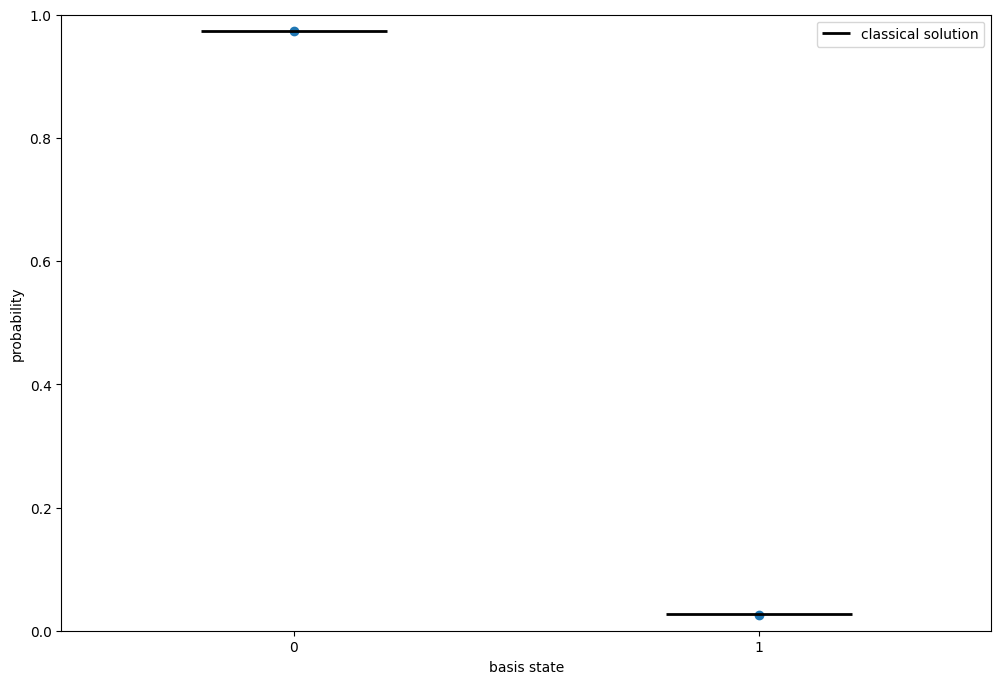

In [6]:
prob_list = []
for i in range(0, 1):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.0539125955565396e-15
       x: [ 4.382e+00]
     nit: 38
   maxcv: 0.0
    nfev: 26
[{'0': 0.9726, '1': 0.0274}]
classical probabilities: [0.97297297 0.02702703]


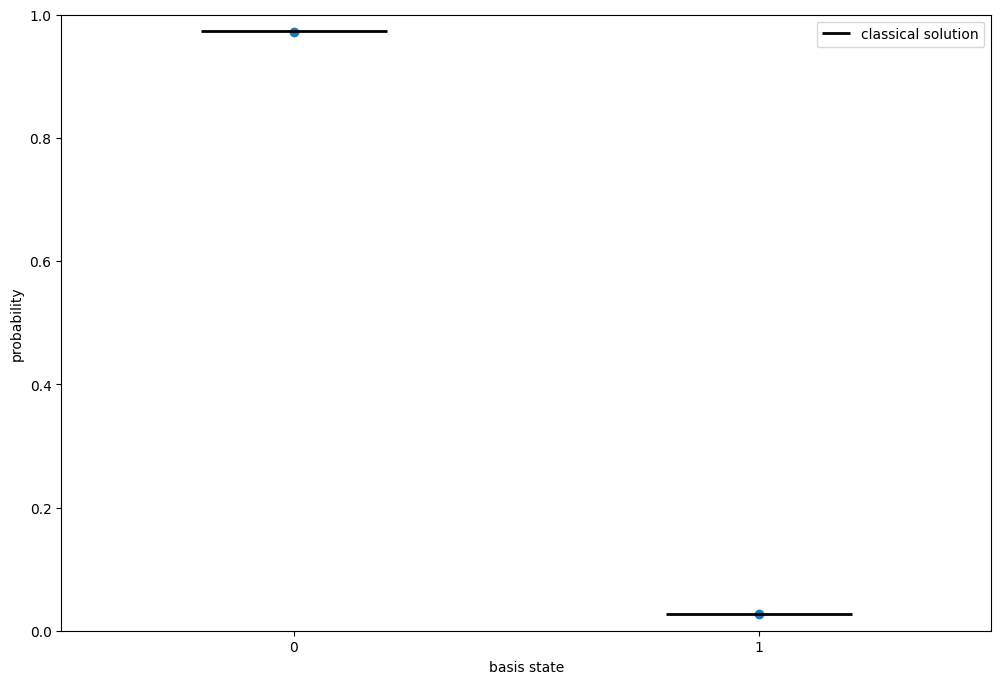

In [7]:
prob_list = []
for i in range(0, 1):
    res = vqls.solve(A, b)
    prob_list.append(res.get_probabilities())

print(prob_list)

# classical solution -> probabilities |x_i|^2 / ||x||^2
x_classical = np.linalg.solve(A, b).reshape(-1)
p_classical = np.abs(x_classical)**2 / np.sum(np.abs(x_classical)**2)
print(f"classical probabilities: {p_classical}")

fig, ax = plt.subplots(figsize=(12, 8))
# short horizontal line centered on each basis state at its classical probability
ax.hlines(p_classical, [-0.2, 0.8], [0.2, 1.2], colors="black", linewidth=2, label="classical solution")

for probs in prob_list:
    p = [probs.get("0", 0), probs.get("1", 0)]
    ax.scatter([0, 1], p)

ax.set_xticks([0, 1])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_xlabel("basis state")
ax.set_ylabel("probability")
ax.legend()
plt.show()

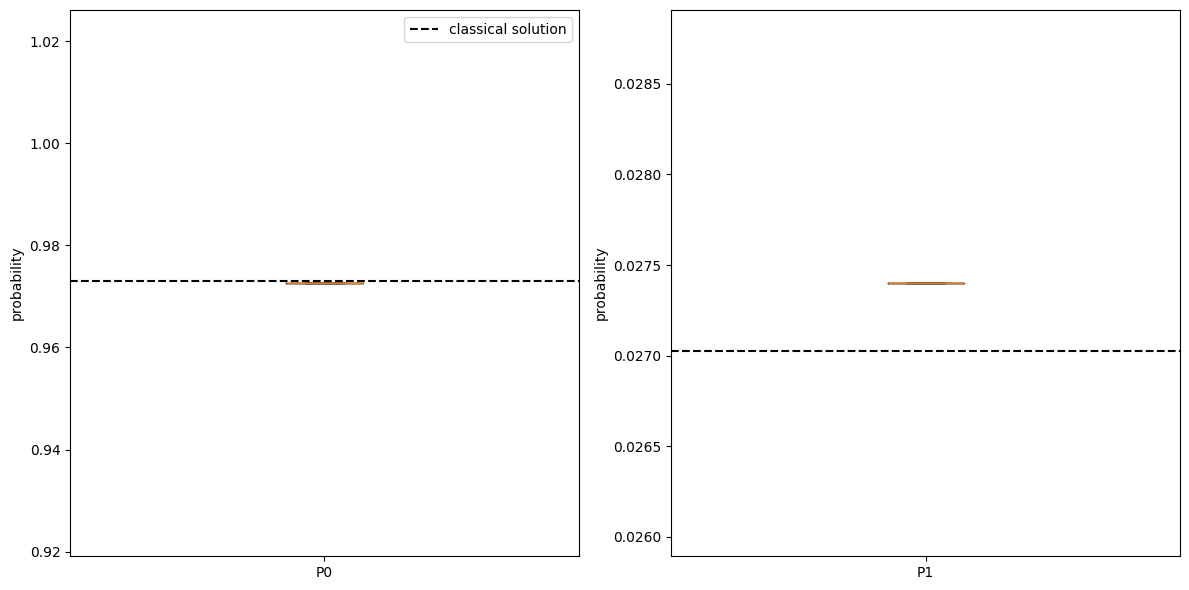

In [8]:
P0s = [probs.get("0", 0) for probs in prob_list]
P1s = [probs.get("1", 0) for probs in prob_list]

# separate panels: P0 and P1 are ~0.6 apart, so a shared axis would squash both boxes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, data, p_true, label in zip(axes, [P0s, P1s], p_classical, ["P0", "P1"]):
    ax.boxplot(data)
    ax.axhline(p_true, color="black", linestyle="--", linewidth=1.5, label="classical solution")
    ax.set_xticks([1])
    ax.set_xticklabels([label])
    ax.set_ylabel("probability")

axes[0].legend()
plt.tight_layout()
plt.show()

# testing 1 qubit vqls on a suite of real and then complex matrices

In [9]:
random_c = lambda: random.random() + 1j * random.random()
random_r = random.random

A = np.array([
    [1, random_c()],
    [1, 1]
])
b = 1/np.sqrt(2) * np.array([
    [1],
    [1]
])
print(A)
qres = vqls.solve(A, b).solution()#.reshape(-1, 1)
cres = np.linalg.solve(A,b)
print(f"Quantum Solution: \n{qres}\n")
print(f"Classical Solution: \n{cres}\n")

# project qres onto cres
np.linalg.norm(qres - cres)

[[1.        +0.j        0.57763956+0.9584234j]
 [1.        +0.j        1.        +0.j       ]]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 2.220446049250313e-16
       x: [-1.571e+00]
     nit: 41
   maxcv: 0.0
    nfev: 19
Quantum Solution: 
[[7.07106780e-01-4.79184091e-10j]
 [9.99942389e-10-6.77629600e-19j]]

Classical Solution: 
[[0.70710678+0.j]
 [0.        +0.j]]



np.float64(1.3607598503395325e-09)

In [10]:
def res_diff(x, y):
    return 1 - np.linalg.norm(x-y)

def test_vqls(b=None, shots=1):
    Ai = [ # random data set of matrices
        np.array([
            [1, random_c()],
            [random_c(), random_c()]
        ]) for _ in range(shots)
    ]

    if b is None:
        b = 1/np.sqrt(2) * np.array([
            [1],
            [1]
        ])

    accuracies = []
    for A in Ai:
        # print(b)
        q_soln = vqls.solve(A, b).solution()
        c_soln = np.linalg.solve(A, b)
        # print(f"Quantum Solution: \n{q_soln}\n")
        # print(f"Classical Solution: \n{c_soln}\n")

        diff = res_diff(q_soln, c_soln)
        # print(f"Accuracy: {diff}")
        accuracies.append(diff)

    # print(accuracies)

    return accuracies

accuracies = test_vqls()
avg_diff = sum(accuracies) / len(accuracies)

print(f"Average Quantum Solution Accuracy: {avg_diff*100:.2f}%")

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.0020662160727432655
       x: [-2.974e+00]
     nit: 42
   maxcv: 0.0
    nfev: 23
Average Quantum Solution Accuracy: 81.12%


In [11]:
avg_diff, accuracies

(np.float64(0.8112131955173999), [np.float64(0.8112131955173999)])

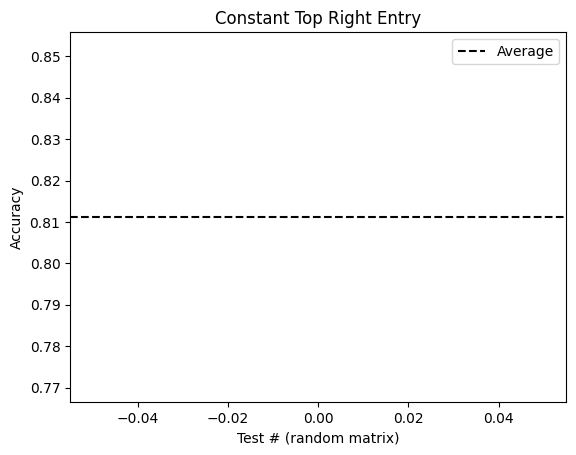

In [12]:
plt.plot(np.linspace(0, len(accuracies), 1), accuracies)
plt.axhline(avg_diff, color='black', linestyle='--', label="Average")
plt.ylabel("Accuracy")
plt.xlabel("Test # (random matrix)")
plt.title("Constant Top Right Entry")
plt.legend()

[array([[0.59228546+0.71125774j, 0.27637806+0.00917146j],
       [0.27622931+0.98343742j, 0.86423821+0.95105811j]])]
 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 0.04514797600937137
       x: [-1.476e+00]
     nit: 36
   maxcv: 0.0
    nfev: 21
0.5972918672664866
Average Accuracy = 0.5972918672664866


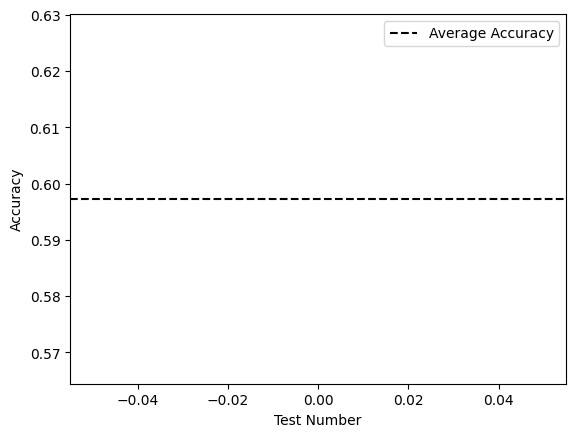

In [13]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0)
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1)

data = vqls.generate_dataset(random_entries=[1+1j, 2+1j, 3+1j, 4+1j], shots=1)
print(data[:3])

# 1 param ansatz ry h
accuracies = vqls_ry.accuracy_test(data)
vqls_ry.plot_tests(accuracies)

 message: The lower bound for the trust-region radius has been reached
 success: True
  status: 0
     fun: 5.551115123125783e-16
       x: [-8.521e-01 -1.724e+00]
     nit: 56
   maxcv: 0.0
    nfev: 44
0.9999999843151168
Average Accuracy = 0.9999999843151168


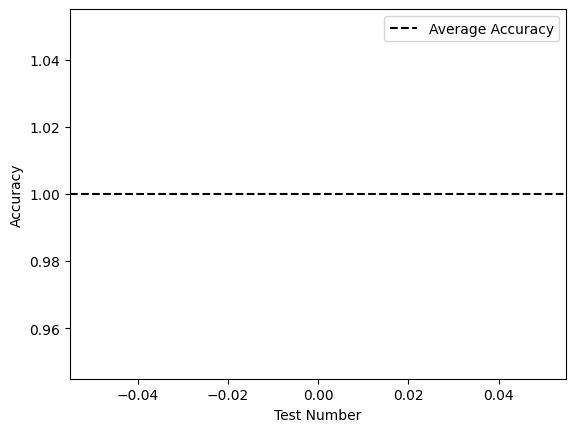

In [14]:
# 2 param ansatz rz ry h
accuracies = vqls_rz.accuracy_test(data)
vqls_rz.plot_tests(accuracies)

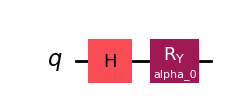

In [15]:
vqls_ry.ansatz.draw('mpl')

In [19]:
generators = oasis_dla.extract_generators(vqls_ry.ansatz)
print(generators)
dla_ry = oasis_dla.construct_dla(generators)
dla_ry

linear_indep(generators)

[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]]), array([[0.+0.j, 0.-1.j],
       [0.+1.j, 0.+0.j]])]
[array([[-1.+0.j,  1.+0.j],
       [ 1.+0.j,  1.+0.j]])]


AttributeError: 'list' object has no attribute 'flatten'

In [ ]:
generators = oasis_dla.extract_generators(vqls_rz.ansatz)
generators
# dla_rz = oasis_dla.construct_dla(generators)
# dla_rz

[array([[-1.+0.j,  1.+0.j],
        [ 1.+0.j,  1.+0.j]]),
 array([[0.+0.j, 0.-1.j],
        [0.+1.j, 0.+0.j]]),
 array([[ 1.+0.j,  0.+0.j],
        [ 0.+0.j, -1.+0.j]])]